In [1]:
# This notebook generates scanned text pages from a video file.
# Algorithm at a high-level
# Extract all frames in a video file
# for each frame in the video file
#   Use SAM model to get the list of masks
#   Filter out masks that are smaller with respect to the frame size OR
#              masks that are not closed (no of False in the bbox are > X * area)
#   Collect list of unique pages using skimage.metrics.structural_similarity
# SAM model (https://github.com/facebookresearch/segment-anything)

In [2]:
import os
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2
from skimage.metrics import structural_similarity as ssim

In [3]:
# Video file to process
video_file = "../data/notebook.mp4"
output_dir = "trash"

# Folders in the output directory
# final - list of unique pages in the video file
# frames - all frames in the video file
# pages - pages in all frames
for d in ["final", "frames", "pages"]:
    os.makedirs(output_dir + "/" + d, exist_ok=True)

In [4]:
def video_to_frames(video_file):
    vidcap = cv2.VideoCapture(video_file)

    frames = []

    while True:
        success, image = vidcap.read()
        if success:
            frames.append(image)
        else:
            break

    return frames

def save_images(images, output_dir):
    for i, f in enumerate(images):
        cv2.imwrite(f"{output_dir}/{i:05d}.jpg", f)

In [5]:
frames = video_to_frames(video_file)
save_images(frames, output_dir + "/frames")

In [6]:
print(f"No of frames {len(frames)}")

No of frames 167


In [7]:
sample_frame = frames[0]

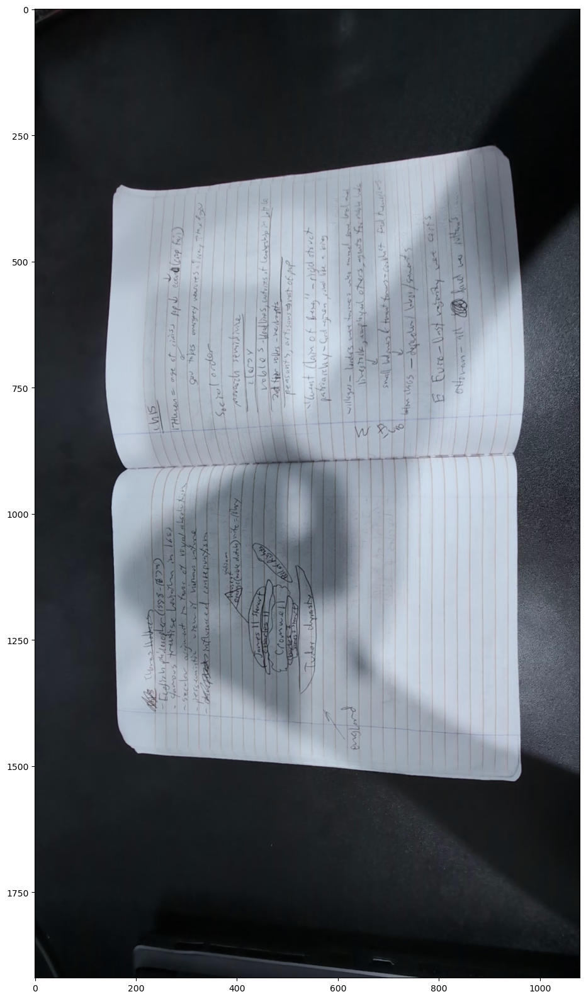

In [8]:
plt.figure(figsize=(20,20))
plt.imshow(sample_frame)
# plt.axis('off')
plt.show()

In [9]:
import sys
sys.path.append("..")
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

/home/neel/anaconda3/lib/python3.12/site-packages/segment_anything/build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(f)


In [10]:
# Filter out the masks to get the list of potential page(s)
# Return of a list of masks that are potential pages
# Consider the masks whose area > apct * frame_size
# Accept a mask that has < X (area * fpct) number of False inside the bbox
def get_pages(masks, apct, fpct):
    p = []
    if len(masks) == 0:
        return p

    frame_size = masks[0]['segmentation'].size

    for m in masks:
        if m['area'] > frame_size * apct:
            bbox = m['bbox']
            num_falses = np.count_nonzero(m['segmentation'][bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == False)
            if num_falses < m['area'] * fpct:
                p.append(m)
    return p

def save_pages(frame, frame_num, pages):
    images = []
    for p in pages:
        bbox = p['bbox']
        images.append(frame[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]])
    
    for i, f in enumerate(images):
        cv2.imwrite(f"{output_dir}/pages/{frame_num:05d}-{i:05d}.jpg", f)

# If two pages are in a frame, then there maybe 3 segments
# 1. covering both pages
# 2. page 1
# 3. page 2
# Filter out the page #1, since the bbox is covered by #2 + #3
def filter_covered_pages(pages, tpct):
    filtered = []
    if len(pages) == 0:
        return filtered

    img_mask = np.full(pages[0]['segmentation'].shape, False)

    for p in sorted(pages, key=(lambda x: x['area'])):
        bbox = p['bbox']
        num_trues = np.count_nonzero(img_mask[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]] == True)
        if num_trues < p['area'] * tpct:
            filtered.append(p)
        img_mask[p['segmentation']] = True
    return filtered

def imshow(image):
    plt.figure(figsize=(20,20))
    plt.imshow(image)
    # plt.axis('off')
    plt.show()

def image_diff_ssim(image1, image2):
    img1 = image1
    img2 = cv2.resize(image2, (img1.shape[1], img1.shape[0]))

    # Convert to grayscale
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    # Compute the SSIM score
    score, diff = ssim(gray1, gray2, full=True)
    diff = (diff * 255).astype("uint8")

    # print("SSIM score:", score)

    # Display the difference image
    # imshow(diff)

    return score

In [11]:
def show_anns(anns):
    if len(anns) == 0:
        return
    ax = plt.gca()
    #ax.set_autoscale_on(False)

    img = np.ones((anns[0]['segmentation'].shape[0], anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0
    for ann in anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)

In [12]:
t1 = time.monotonic_ns()
masks = mask_generator.generate(sample_frame)
t2 = time.monotonic_ns()
print(f"Time takes in generating masks {(t2 - t1) / 1000000} milli seconds")
masks = sorted(masks, key=(lambda x: x['area']), reverse=True)
print(f"No of masks {len(masks)}")

Time takes in generating masks 8340.389835 milli seconds
No of masks 19


In [13]:
pages = get_pages(masks, 0.20, 0.20)
len(pages)

3

In [14]:
for p in pages:
    print(f"{p['bbox']}")
    

[142, 274, 826, 1254]
[154, 884, 806, 644]
[143, 274, 823, 635]


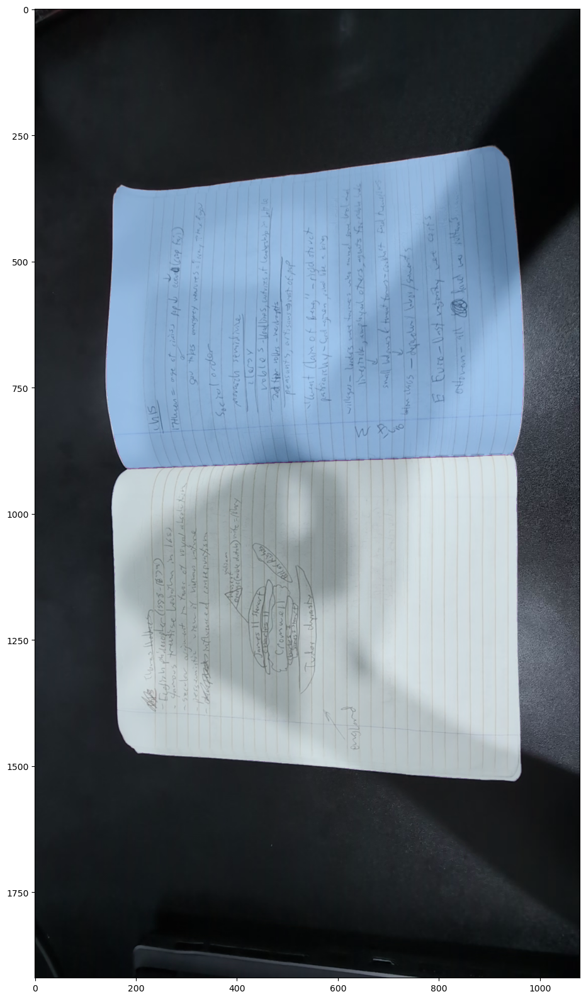

In [15]:
# Show the frame annotated with all masks
plt.figure(figsize=(20,20))

# Show the image
plt.imshow(sample_frame)

# Annonate list of masks
show_anns(pages)

#plt.axis('off')
plt.show() 

In [16]:
filtered_pages = filter_covered_pages(pages, 0.20)

In [17]:
len(filtered_pages)

2

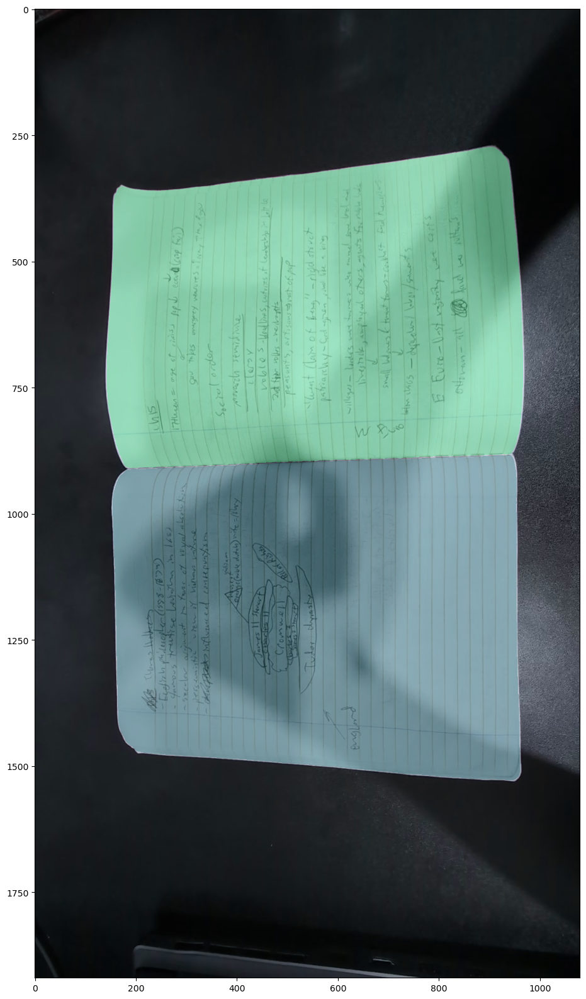

In [18]:
plt.figure(figsize=(20,20))
plt.imshow(sample_frame)
show_anns(filtered_pages)
plt.show()

In [19]:
save_pages(sample_frame, 0, filtered_pages)

In [20]:
bbox = filtered_pages[0]['bbox']
print(bbox)
sample_frame[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]].shape

[143, 274, 823, 635]


(635, 823, 3)

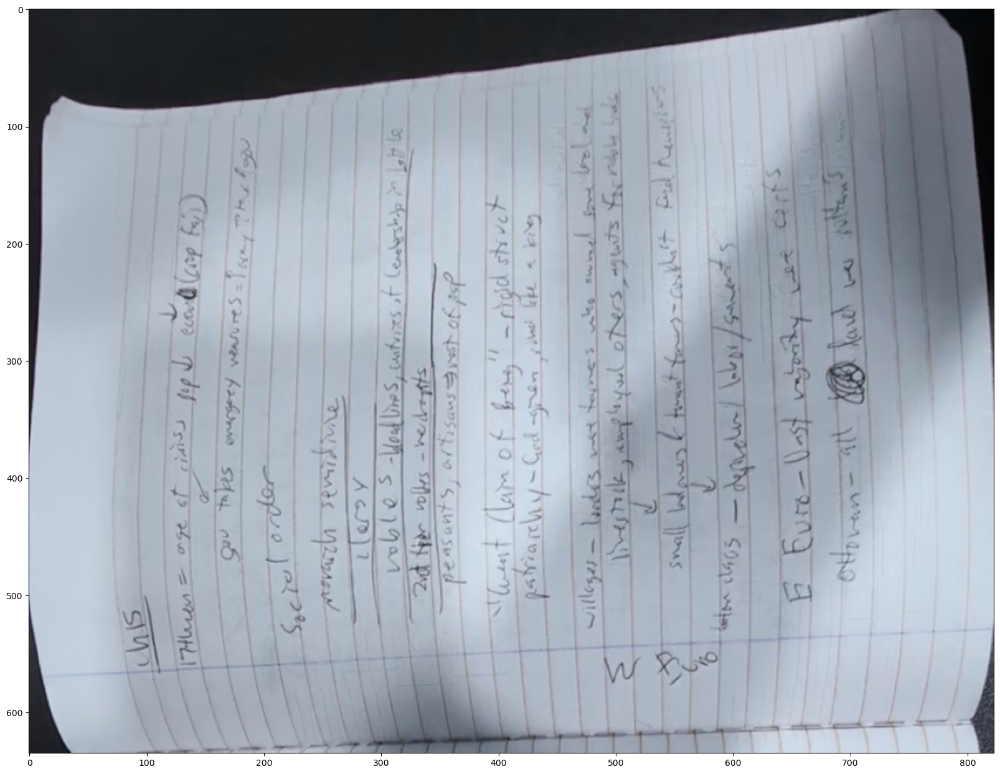

In [21]:
plt.figure(figsize=(20,20))
plt.imshow(sample_frame[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]])
plt.show()

In [22]:
def find_match(scanned_pages, ssim_similarity_threshold, page):
    for p in scanned_pages:
        if image_diff_ssim(p, page) > ssim_similarity_threshold:
            return True
    return False

def add_if_new_page(scanned_pages, scanned_page_names, ssim_similarity_threshold, page, page_name):
    
    if not find_match(scanned_pages, ssim_similarity_threshold, page):
        print(f"Found a new page {page_name}")
        scanned_pages.append(page)
        scanned_page_names.append(page_name)
    else:
        print(f"Page {page_name} is duplicate, skipping")

def save_final_images(scanned_pages, scanned_page_names):
    for i, p in enumerate(scanned_pages):
        cv2.imwrite(scanned_page_names[i], p)
    print(f"No of scanned pages are: {len(scanned_pages)}, files are saved {scanned_page_names}")

def process_all_frames():
    apct = 0.20 # Select masks that are apct of total frame area
    fpct = 0.20 # Select masks that have less than area * fpct of False values inside the bbox
    tpct = 0.20 # Select masks that have less than area * tpct of True values covered pixels

    scanned_pages = []
    scanned_page_names = []
    ssim_similarity_threshold = 0.8
    previous_pages = 0
    
    for i, f in enumerate(frames):
        t1 = time.monotonic_ns()
        masks = mask_generator.generate(f)
        t2 = time.monotonic_ns()
        print(f"Frame {i:05d} no of masks {len(masks)}")
        print(f"Time takes in generating masks {(t2 - t1) / 1000000} milli seconds")
        pages = get_pages(masks, apct, fpct)
        print(f"Frame {i:05d} no of pages {len(pages)}")
        filtered = filter_covered_pages(pages, tpct)
        print(f"Frame {i:05d} no of filtered pages {len(filtered)}")
        save_pages(f, i, filtered)

        if previous_pages != len(filtered):
            for fi, ff in enumerate(filtered):
                bbox = ff['bbox']
                ff = f[bbox[1]:bbox[1]+bbox[3], bbox[0]:bbox[0]+bbox[2]]
                add_if_new_page(scanned_pages, scanned_page_names, ssim_similarity_threshold, ff, f"{output_dir}/final/{i:05d}-{fi:05d}.jpg")

        previous_pages = len(filtered)

    save_final_images(scanned_pages, scanned_page_names)
    return scanned_pages

In [23]:
scanned_pages = process_all_frames()

Frame 00000 no of masks 19
Time takes in generating masks 7810.308467 milli seconds
Frame 00000 no of pages 3
Frame 00000 no of filtered pages 2
Found a new page trash/final/00000-00000.jpg
Found a new page trash/final/00000-00001.jpg
Frame 00001 no of masks 16
Time takes in generating masks 7669.825294 milli seconds
Frame 00001 no of pages 3
Frame 00001 no of filtered pages 2
Frame 00002 no of masks 15
Time takes in generating masks 7629.865424 milli seconds
Frame 00002 no of pages 3
Frame 00002 no of filtered pages 2
Frame 00003 no of masks 17
Time takes in generating masks 7621.244753 milli seconds
Frame 00003 no of pages 3
Frame 00003 no of filtered pages 2
Frame 00004 no of masks 24
Time takes in generating masks 7735.725093 milli seconds
Frame 00004 no of pages 3
Frame 00004 no of filtered pages 2
Frame 00005 no of masks 19
Time takes in generating masks 7654.578613 milli seconds
Frame 00005 no of pages 3
Frame 00005 no of filtered pages 2
Frame 00006 no of masks 17
Time takes in

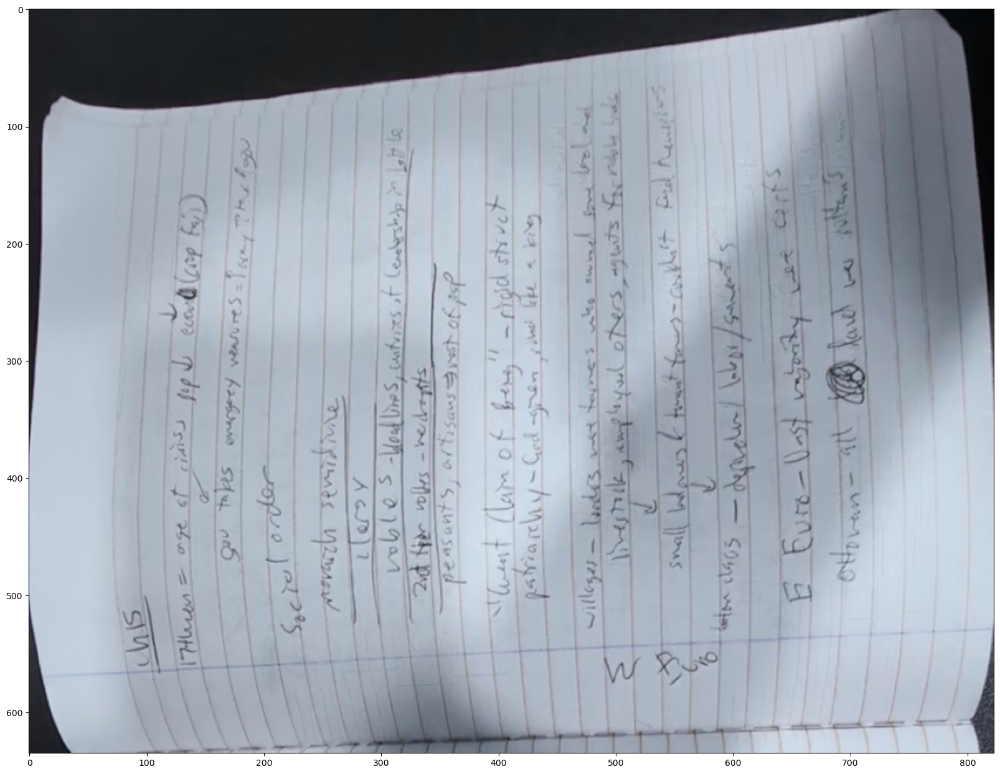

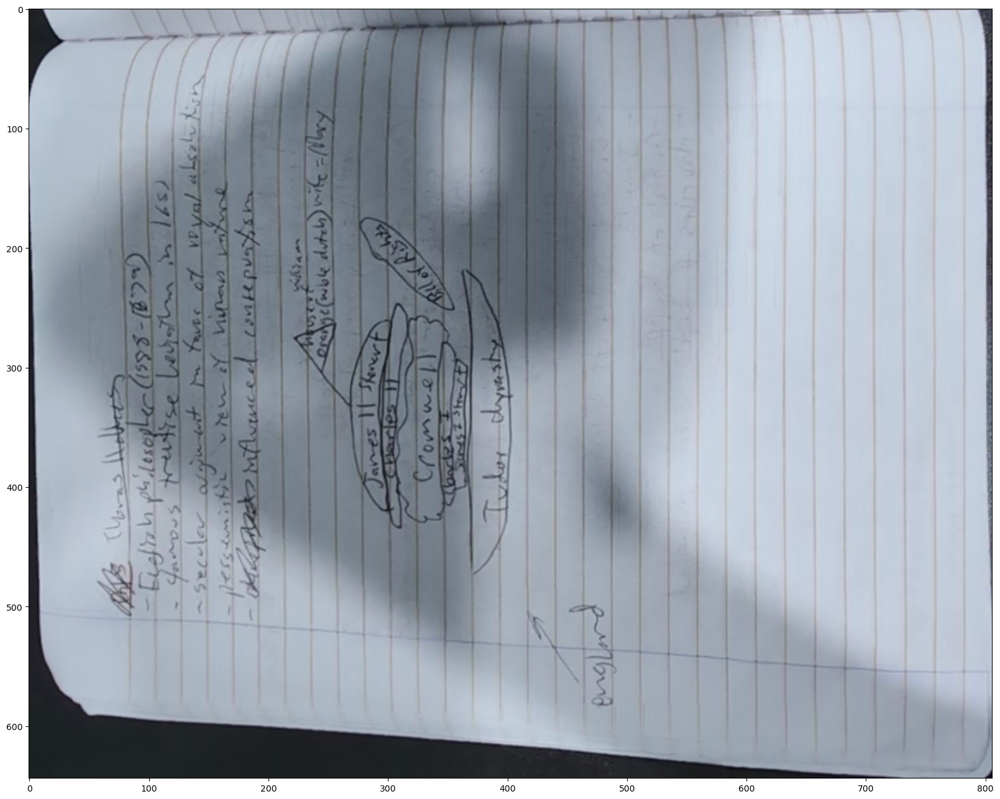

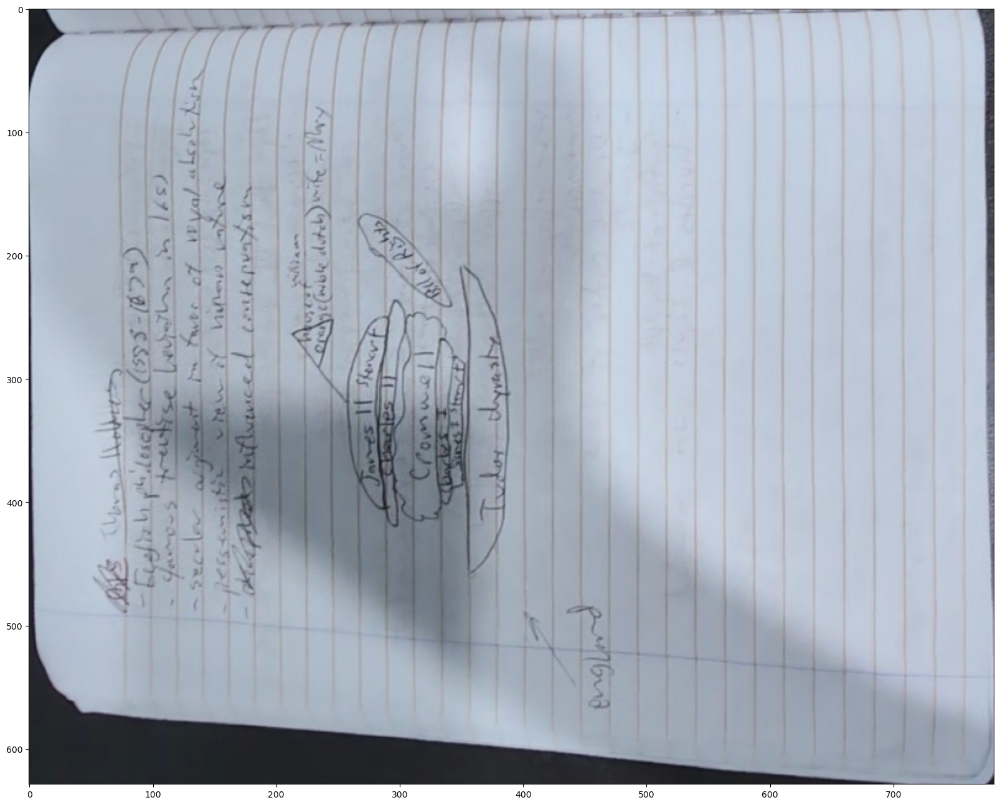

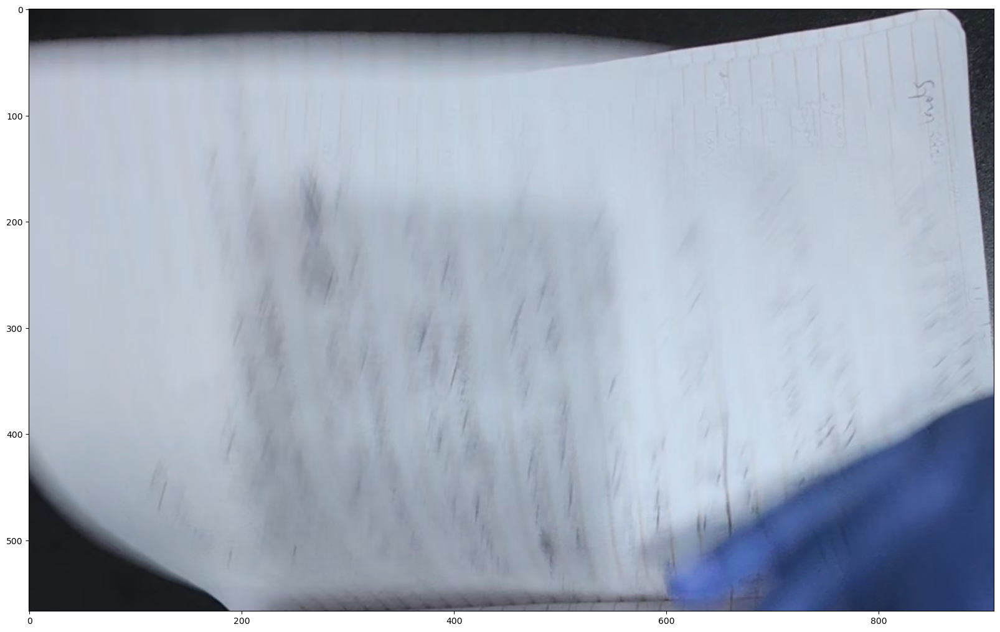

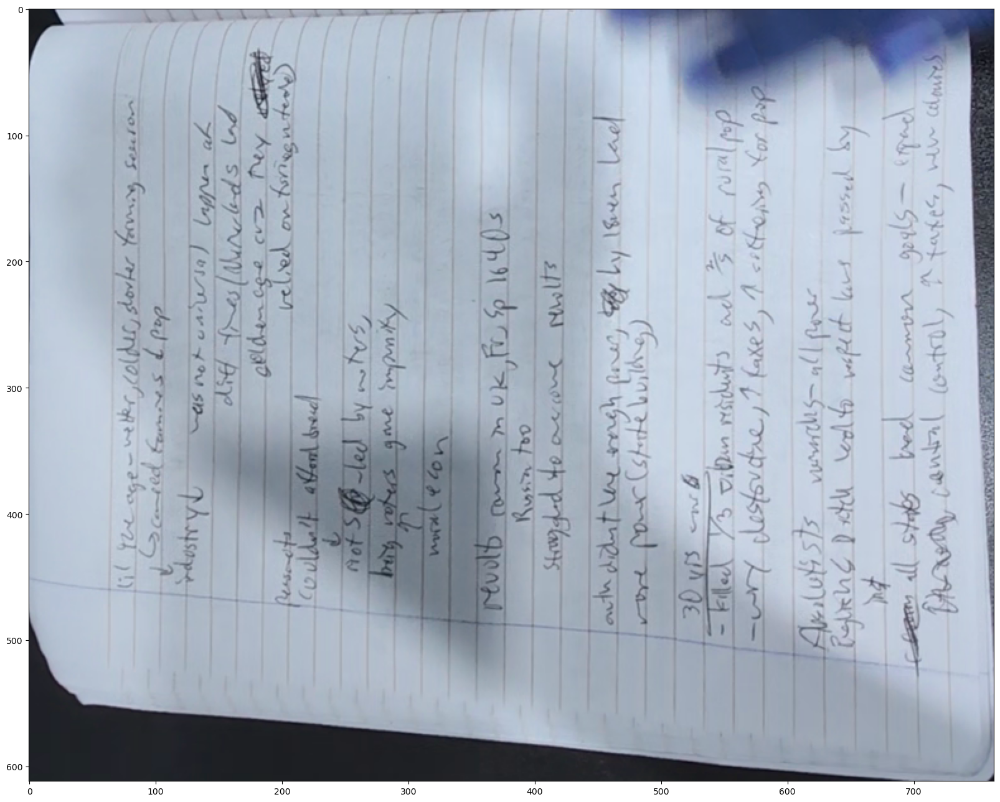

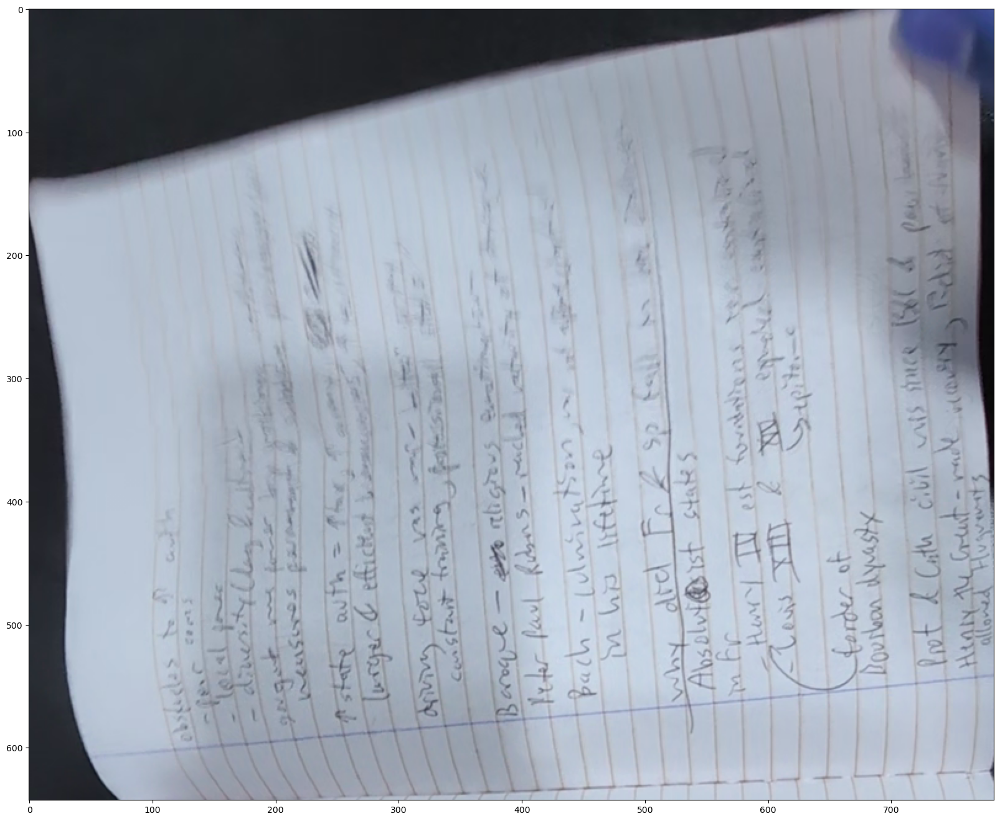

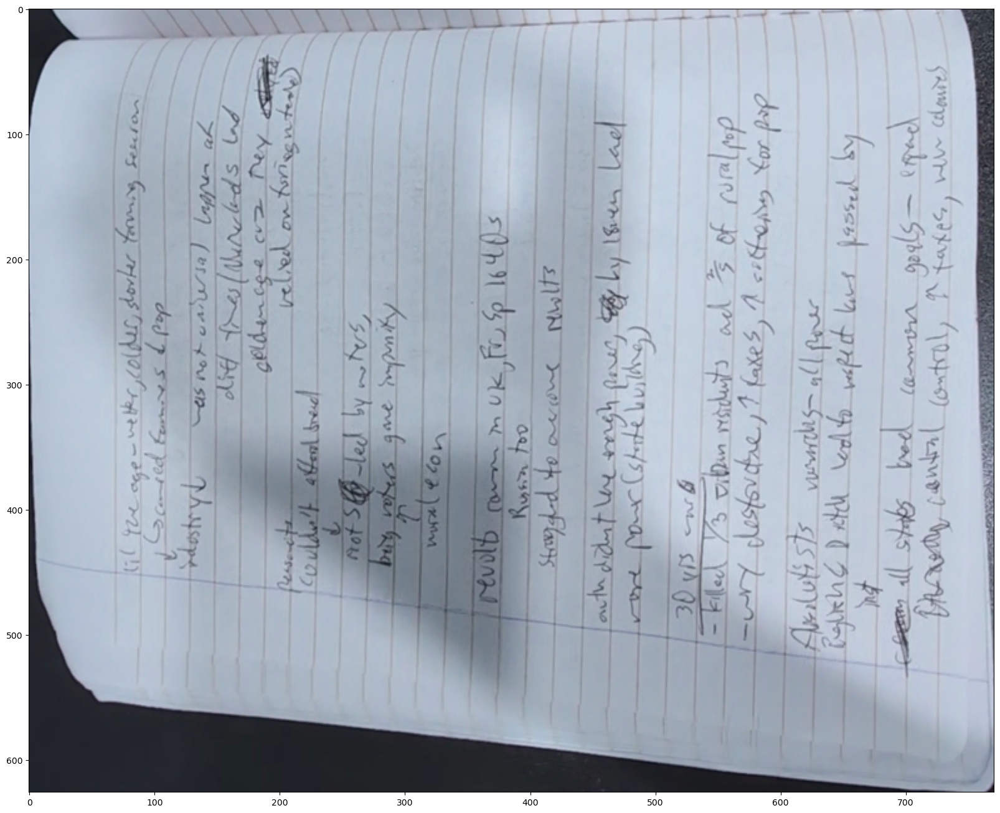

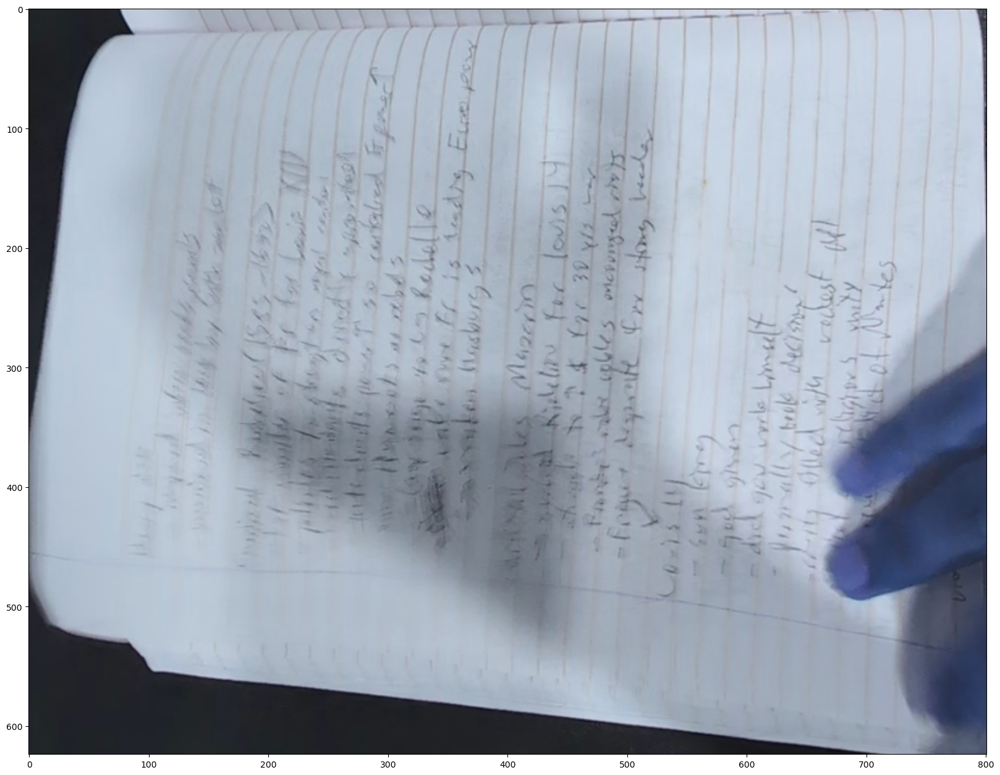

In [24]:
for p in scanned_pages:
    imshow(p)